<a href="https://colab.research.google.com/github/par-hub/hate-sarcasm-detection./blob/main/hate_sarcasm_improved_(1)claud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Improved Hate Speech Detection with Sarcasm Rationales

Reproduces and improves *"Hate Speech Detection by Using Rationales for Judging Sarcasm"* (Mamun et al., Appl. Sci. 2024, 14, 4898) using **your own annotation file `sarcasm_manual_3199_2.csv`** (3,199 posts with `label`, `sarcasm_label`, `sarcasm_rationale`).

**What the paper does:** BERT + attention supervision on the `[CLS]` attention of the last layer; ground-truth attention built from hate/offensive rationales and, for toxic+sarcastic posts, a combined rationale `r = h + 0.5*s` (values 0.5 / 1 / 1.5). Reported gain: macro-F1 0.6883 -> 0.6983.

**What this notebook changes:**

| # | Improvement | Why it should help |
|---|---|---|
| 1 | Stronger backbone (`roberta-base`; HateBERT / Twitter-RoBERTa optional) | Better on noisy social-media text than plain BERT |
| 2 | Warmup + linear LR decay, weight decay, grad clipping, fp16, batch 16 | Paper used batch 4: noisy and slow |
| 3 | Early stopping on validation macro-F1 | Avoids over/under-training |
| 4 | Class-weighted CE + label smoothing | Offensive class is small (F1 ~0.51 in the paper) |
| 5 | KL attention loss with larger lambda (paper: 0.001, almost no effect) | Attention supervision actually shapes the model |
| 6 | Auxiliary **sarcasm-prediction head** (uses your `sarcasm_label`) | Explicit sarcasm signal for the encoder |
| 7 | **5-fold cross-validation** instead of a single 300-post test set | Only 216 toxic+sarcastic posts exist; a 300-post test set cannot resolve a 0.01 gain |
| 8 | Explainability metrics from the model's own attention + a "hidden hate" metric on toxic+sarcastic posts | Measures the thing the paper actually cares about |

**Data note.** Your file has 448 sarcastic posts (216 of them toxic), not the 1487 / 755 quoted in the paper's Table 1, so the sarcasm effect is expected to be small and noisy. That is why cross-validation and the sarcastic-subset metric are included.

## 1. Setup

In [ ]:
!pip -q install transformers accelerate scikit-learn pandas matplotlib

In [ ]:
import os, json, random, difflib, urllib.request, warnings
from collections import Counter
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_recall_curve, auc
warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

CFG = dict(
    csv_path="sarcasm_manual_3199_2.csv",   # your annotation file (upload it to Colab / put next to the notebook)
    backbone="roberta-base",     # also try: "GroNLP/hateBERT", "bert-base-uncased", "cardiffnlp/twitter-roberta-base-hate"
    max_len=128, batch_size=16, lr=2e-5, epochs=6, warmup=0.1, wd=0.01, label_smoothing=0.05,
    sup_heads=6,                 # supervised heads in the last layer (as in the paper)
    tau=0.3,                     # softmax temperature for ground-truth attention (smaller = sharper)
    lam=1.0,                     # attention-loss weight (paper: 0.001)
    aux_w=0.3,                   # weight of the auxiliary sarcasm head
    topk=5,                      # rationale size for explainability metrics (paper: top 5 tokens)
    cv_folds=5,                  # 5 = stratified 5-fold CV; 1 = single 2599/300/300 split like the paper
    seeds=[42],                  # model seeds per fold (add 43, 44 for more stable numbers)
    quick=True,                  # True = smoke test (first fold only, 1 epoch). Set False for the full run.
)
if CFG["quick"]:
    CFG.update(epochs=1)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda


## 2. Load your annotation file + HateXplain human rationales

In [ ]:
# --- your sarcasm file ---
if not os.path.exists(CFG["csv_path"]):
    try:
        from google.colab import files
        print("Upload", CFG["csv_path"]); up = files.upload(); CFG["csv_path"] = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError("Put sarcasm_manual_3199_2.csv next to this notebook or fix CFG['csv_path'].")
sd = pd.read_csv(CFG["csv_path"])
print(sd.shape, "| sarcastic:", (sd.sarcasm_label == "sarcasm").sum())

# --- HateXplain (public): annotator labels + hate/offensive rationales, joined by post_id ---
BASE = "https://raw.githubusercontent.com/hate-alert/HateXplain/master/Data/"
if not os.path.exists("dataset.json"):
    urllib.request.urlretrieve(BASE + "dataset.json", "dataset.json")
raw = json.load(open("dataset.json"))
LAB = {"normal": 0, "hatespeech": 1, "offensive": 2}
INV = {v: k for k, v in LAB.items()}

def span_to_mask(tokens, span):
    """Map your sarcasm_rationale text span onto HateXplain word positions."""
    s = np.zeros(len(tokens), dtype=np.float32)
    if not isinstance(span, str) or not span.strip(): return s
    sp = span.split(); n = len(sp)
    for i in range(len(tokens) - n + 1):               # exact word-sequence match (441/448 spans)
        if tokens[i:i+n] == sp:
            s[i:i+n] = 1; return s
    sm = difflib.SequenceMatcher(None, tokens, sp, autojunk=False)   # fuzzy fallback (spans with '...' etc.)
    for blk in sm.get_matching_blocks():
        if blk.size >= 2: s[blk.a:blk.a+blk.size] = 1
    return s

def build_post(r):
    d = raw[r.post_id]
    labels = [a["label"] for a in d["annotators"]]
    lab, c = Counter(labels).most_common(1)[0]
    toks = d["post_tokens"]; n = len(toks)
    if c < 2 or n == 0:                                  # 'undecided' posts are dropped
        return None
    h = np.zeros(n, dtype=np.float32)
    if lab != "normal":
        rats = [np.array(x, dtype=np.float32) for x in d["rationales"] if len(x) == n]
        if rats: h = np.mean(rats, axis=0)               # mean of annotator rationale vectors
    sarc = int(r.sarcasm_label == "sarcasm")
    s = span_to_mask(toks, r.sarcasm_rationale) if sarc else np.zeros(n, dtype=np.float32)
    return dict(id=r.post_id, tokens=toks, label=LAB[lab], h=h, s=s, sarc=sarc)

posts = [p for p in (build_post(r) for r in sd.itertuples()) if p is not None]
print(len(posts), "posts |", Counter(INV[p["label"]] for p in posts))
print("toxic & sarcastic:", sum(1 for p in posts if p["sarc"] and p["label"] != 0),
      "| with sarcasm rationale:", sum(1 for p in posts if p["sarc"] and p["s"].sum() > 0))

Upload sarcasm_manual_3199_2.csv


Saving sarcasm_manual_3199 (2).csv to sarcasm_manual_3199 (2).csv
(3199, 5) | sarcastic: 448
3189 posts | Counter({'normal': 1552, 'hatespeech': 1193, 'offensive': 444})
toxic & sarcastic: 216 | with sarcasm rationale: 445


## 3. Splits (stratified by label x sarcasm)

In [ ]:
strat = [f'{p["label"]}_{p["sarc"]}' for p in posts]
def make_splits():
    out = []
    if CFG["cv_folds"] > 1:
        skf = StratifiedKFold(CFG["cv_folds"], shuffle=True, random_state=0)
        for trv, te_i in skf.split(posts, strat):
            tr_i, va_i = train_test_split(trv, test_size=0.1, stratify=[strat[i] for i in trv], random_state=0)
            out.append(([posts[i] for i in tr_i], [posts[i] for i in va_i], [posts[i] for i in te_i]))
    else:
        idx = np.arange(len(posts))
        rest, te_i = train_test_split(idx, test_size=300, stratify=strat, random_state=0)
        tr_i, va_i = train_test_split(rest, test_size=300, stratify=[strat[i] for i in rest], random_state=0)
        out.append(([posts[i] for i in tr_i], [posts[i] for i in va_i], [posts[i] for i in te_i]))
    return out
SPLITS = make_splits()
if CFG["quick"]: SPLITS = SPLITS[:1]
print([(len(a), len(b), len(c)) for a, b, c in SPLITS])

[(2295, 256, 638)]


## 4. Ground-truth attention, batching, model

Combined rationale (paper, Algorithm 1 / Fig. 2): `r = h + 0.5*s` -> sarcasm-only token 0.5, hate-only 1, both 1.5
(the paper's pseudo-code would give 2 for "both", but its text and Fig. 2 say 1.5; this notebook follows the text).
Word values are copied to sub-words and passed through a temperature softmax; normal posts get a uniform target.

In [ ]:
try:    tok = AutoTokenizer.from_pretrained(CFG["backbone"], add_prefix_space=True, use_fast=True)
except Exception: tok = AutoTokenizer.from_pretrained(CFG["backbone"], use_fast=True)

def make_batch(batch, sarc_rat=False):
    enc = tok([p["tokens"] for p in batch], is_split_into_words=True, truncation=True,
              max_length=CFG["max_len"], padding=True, return_tensors="pt")
    B, T = enc["input_ids"].shape
    vals = torch.zeros(B, T); wm = torch.zeros(B, T); wids = []
    for i, p in enumerate(batch):
        v = p["h"] + (0.5 * p["s"] if sarc_rat else 0.0)
        w_ids = enc.word_ids(i); wids.append(w_ids)
        for j, w in enumerate(w_ids):
            if w is not None:
                wm[i, j] = 1; vals[i, j] = float(v[w])
    tgt = torch.zeros(B, T)
    for i, p in enumerate(batch):
        m = wm[i] > 0
        if p["label"] != 0 and vals[i].sum() > 0:
            tgt[i] = torch.softmax((vals[i] / CFG["tau"]).masked_fill(~m, -1e9), 0)
        else:
            tgt[i] = m.float() / m.sum().clamp(min=1)
    return dict(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], word_mask=wm,
                target=tgt, y=torch.tensor([p["label"] for p in batch]),
                sarc=torch.tensor([p["sarc"] for p in batch]), wids=wids)

def to_dev(b): return {k: (v.to(DEVICE) if torch.is_tensor(v) else v) for k, v in b.items()}

class Net(nn.Module):
    def __init__(self, name, sup_heads):
        super().__init__()
        self.enc = AutoModel.from_pretrained(name, attn_implementation="eager")  # eager -> attention weights available
        H = self.enc.config.hidden_size
        self.drop = nn.Dropout(0.1); self.cls = nn.Linear(H, 3); self.aux = nn.Linear(H, 2); self.sh = sup_heads
    def forward(self, ids, mask, word_mask):
        o = self.enc(input_ids=ids, attention_mask=mask, output_attentions=True)
        h = self.drop(o.last_hidden_state[:, 0])
        att = o.attentions[-1][:, :self.sh, 0, :].float() * word_mask[:, None, :]   # [CLS] row of supervised heads
        att = att / (att.sum(-1, keepdim=True) + 1e-9)
        return self.cls(h), self.aux(h), att

def attention_kl(att, tgt, eps=1e-9):
    t = tgt[:, None, :]
    return (t * (torch.log(t + eps) - torch.log(att + eps))).sum(-1).mean()

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

## 5. Training and evaluation

In [ ]:
def train_one(train, val, sarc_rat, aux, lam, seed):
    set_seed(seed)
    model = Net(CFG["backbone"], CFG["sup_heads"]).to(DEVICE)
    dl = DataLoader(train, batch_size=CFG["batch_size"], shuffle=True,
                    collate_fn=lambda b: make_batch(b, sarc_rat))
    cnt = np.bincount([p["label"] for p in train], minlength=3)
    cw = torch.tensor(len(train) / (3 * cnt), dtype=torch.float).to(DEVICE)
    sc_ = np.bincount([p["sarc"] for p in train], minlength=2)
    cw_s = torch.tensor(len(train) / (2 * sc_), dtype=torch.float).to(DEVICE)
    nd = ["bias", "LayerNorm.weight"]
    params = [{"params": [p for n, p in model.named_parameters() if not any(x in n for x in nd)], "weight_decay": CFG["wd"]},
              {"params": [p for n, p in model.named_parameters() if any(x in n for x in nd)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(params, lr=CFG["lr"])
    total = len(dl) * CFG["epochs"]
    sch = get_linear_schedule_with_warmup(opt, int(CFG["warmup"] * total), total)
    amp = DEVICE == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    best, best_state = -1, None
    for ep in range(CFG["epochs"]):
        model.train()
        for b in dl:
            b = to_dev(b)
            with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                lg, ax, att = model(b["input_ids"], b["attention_mask"], b["word_mask"])
            loss = F.cross_entropy(lg.float(), b["y"], weight=cw, label_smoothing=CFG["label_smoothing"])
            if lam > 0:  loss = loss + lam * attention_kl(att, b["target"])
            if aux:      loss = loss + CFG["aux_w"] * F.cross_entropy(ax.float(), b["sarc"], weight=cw_s)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
        probs, _ = predict(model, val)
        f1 = f1_score([p["label"] for p in val], probs.argmax(1), average="macro")
        print(f"    epoch {ep+1}: val macro-F1 {f1:.4f}")
        if f1 > best:
            best = f1; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model

@torch.no_grad()
def predict(model, plist, bs=64):
    model.eval(); probs, wscores = [], []
    for i in range(0, len(plist), bs):
        chunk = plist[i:i+bs]; b = to_dev(make_batch(chunk))
        lg, _, att = model(b["input_ids"], b["attention_mask"], b["word_mask"])
        probs.append(torch.softmax(lg.float(), -1).cpu())
        a = att.mean(1).cpu().numpy()
        for k, p in enumerate(chunk):
            sc = np.zeros(len(p["tokens"]))
            for j, w in enumerate(b["wids"][k]):
                if w is not None: sc[w] += a[k, j]
            wscores.append(sc)
    return torch.cat(probs).numpy(), wscores

def mk(tokens):
    t = tokens if tokens else [tok.unk_token]
    return dict(tokens=t, h=np.zeros(len(t), dtype=np.float32), s=np.zeros(len(t), dtype=np.float32), label=0, sarc=0)

def explain_eval(model, plist):
    k = CFG["topk"]
    toxic = [p for p in plist if p["label"] != 0 and p["h"].sum() > 0]
    if not toxic: return {}
    probs, ws = predict(model, toxic)
    cls = probs.argmax(1); f1s, aps, tops = [], [], []
    for p, sc in zip(toxic, ws):
        gold = (p["h"] > 0).astype(int); n = len(gold)
        top = np.argsort(-sc)[:min(k, n)]; tops.append(set(top.tolist()))
        pred = np.zeros(n, int); pred[top] = 1
        tp = (pred & gold).sum(); pr = tp / max(pred.sum(), 1); rc = tp / max(gold.sum(), 1)
        f1s.append(0 if tp == 0 else 2 * pr * rc / (pr + rc))
        if 0 < gold.sum() < n:
            pp, rr, _ = precision_recall_curve(gold, sc); aps.append(auc(rr, pp))
    removed = [mk([t for i, t in enumerate(p["tokens"]) if i not in s]) for p, s in zip(toxic, tops)]
    only = [mk([t for i, t in enumerate(p["tokens"]) if i in s]) for p, s in zip(toxic, tops)]
    pr_rem, _ = predict(model, removed); pr_only, _ = predict(model, only)
    idx = np.arange(len(toxic))
    return dict(token_f1=float(np.mean(f1s)), auprc=float(np.mean(aps)),
                comprehensiveness=float(np.mean(probs[idx, cls] - pr_rem[idx, cls])),   # higher is better
                sufficiency=float(np.mean(probs[idx, cls] - pr_only[idx, cls])))        # lower is better

def hidden_hate_stats(y, pred, sarc):
    m = (y != 0) & (sarc == 1)          # toxic AND sarcastic posts = the paper's "hidden hate"
    if m.sum() == 0: return {}
    return dict(hidden_toxic_recall=float(((pred[m] != 0)).mean()),     # share of sarcastic toxic posts flagged as toxic
                hidden_acc=float((pred[m] == y[m]).mean()))

def evaluate(model, test):
    probs, _ = predict(model, test)
    y = np.array([p["label"] for p in test]); sarc = np.array([p["sarc"] for p in test]); pred = probs.argmax(1)
    res = dict(acc=accuracy_score(y, pred), macro_f1=f1_score(y, pred, average="macro"),
               f1_offensive=f1_score(y, pred, average=None, labels=[0, 1, 2])[2],
               auroc=roc_auc_score(y, probs, multi_class="ovr", average="macro"))
    res.update(hidden_hate_stats(y, pred, sarc)); res.update(explain_eval(model, test))
    return res, probs

## 6. Run the experiments

| mode | hate rationale | sarcasm rationale | sarcasm aux head | attention loss |
|---|---|---|---|---|
| `no_att_supervision` | - | - | - | off |
| `baseline_hate_rat` | yes | - | - | on |
| `proposed_sarc_rat` (paper's idea) | yes | yes | - | on |
| `proposed_sarc_rat+aux` (new) | yes | yes | yes | on |

Set `CFG["quick"] = False` in the setup cell for the full run (5 folds x 4 modes; roughly 45-90 min on a Colab T4).

In [ ]:
MODES = {
    "no_att_supervision":     dict(sarc_rat=False, aux=False, lam=0.0),
    "baseline_hate_rat":      dict(sarc_rat=False, aux=False, lam=CFG["lam"]),
    "proposed_sarc_rat":      dict(sarc_rat=True,  aux=False, lam=CFG["lam"]),
    "proposed_sarc_rat+aux":  dict(sarc_rat=True,  aux=True,  lam=CFG["lam"]),
}
rows, oof = [], []     # oof = out-of-fold predictions, pooled over all folds afterwards
for fold, (tr, va, te) in enumerate(SPLITS):
    for name, m in MODES.items():
        for seed in CFG["seeds"]:
            print(f"== fold {fold} | {name} | seed {seed}")
            model = train_one(tr, va, m["sarc_rat"], m["aux"], m["lam"], seed)
            r, probs = evaluate(model, te)
            r.update(mode=name, seed=seed, fold=fold); rows.append(r)
            for p, pr in zip(te, probs):
                oof.append(dict(mode=name, seed=seed, y=p["label"], sarc=p["sarc"], pred=int(pr.argmax()), probs=pr))
            print("   ", {k: round(v, 4) for k, v in r.items() if isinstance(v, float)})
            del model; torch.cuda.empty_cache()
res = pd.DataFrame(rows); res.to_csv("results_per_fold.csv", index=False)

== fold 0 | no_att_supervision | seed 42


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    epoch 1: val macro-F1 0.5826
    {'acc': 0.6426, 'macro_f1': 0.5522, 'f1_offensive': np.float64(0.21), 'auroc': np.float64(0.7773), 'hidden_toxic_recall': 0.7442, 'hidden_acc': 0.4884, 'token_f1': 0.427, 'auprc': 0.6283, 'comprehensiveness': 0.2261, 'sufficiency': 0.0451}
== fold 0 | baseline_hate_rat | seed 42


... (5 outputs left out)

    epoch 1: val macro-F1 0.6175
    {'acc': 0.674, 'macro_f1': 0.5811, 'f1_offensive': np.float64(0.2383), 'auroc': np.float64(0.7935), 'hidden_toxic_recall': 0.7209, 'hidden_acc': 0.5349, 'token_f1': 0.4822, 'auprc': 0.7827, 'comprehensiveness': 0.4059, 'sufficiency': 0.0207}
== fold 0 | proposed_sarc_rat+aux | seed 42


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    epoch 1: val macro-F1 0.6122
    {'acc': 0.6771, 'macro_f1': 0.5858, 'f1_offensive': np.float64(0.2487), 'auroc': np.float64(0.7937), 'hidden_toxic_recall': 0.7442, 'hidden_acc': 0.5814, 'token_f1': 0.4832, 'auprc': 0.7847, 'comprehensiveness': 0.4037, 'sufficiency': 0.0187}


## 7. Results

Per-fold mean +- std (explainability metrics come from here)


acc     macro_f1     f1_offensive       auroc      \
                         mean std     mean std         mean std    mean std   
mode                                                                          
baseline_hate_rat      0.6708 NaN   0.5765 NaN       0.2280 NaN  0.7932 NaN   
no_att_supervision     0.6426 NaN   0.5522 NaN       0.2100 NaN  0.7773 NaN   
proposed_sarc_rat      0.6740 NaN   0.5811 NaN       0.2383 NaN  0.7935 NaN   
proposed_sarc_rat+aux  0.6771 NaN   0.5858 NaN       0.2487 NaN  0.7937 NaN   

                      hidden_toxic_recall     token_f1       auprc      \
                                     mean std     mean std    mean std   
mode                                                                     
baseline_hate_rat                  0.7209 NaN   0.4824 NaN  0.7843 NaN   
no_att_supervision                 0.7442 NaN   0.4270 NaN  0.6283 NaN   
proposed_sarc_rat                  0.7209 NaN   0.4822 NaN  0.7827 NaN   
proposed_sarc_rat+aux              0.7442 NaN   0.4832 NaN  0.7847 NaN   

                      comprehensiveness     sufficiency      
                                   mean std        mean std  
mode                                                         
baseline_hate_rat                0.4124 NaN      0.0160 NaN  
no_att_supervision               0.2261 NaN      0.0451 NaN  
proposed_sarc_rat                0.4059 NaN      0.0207 NaN  
proposed_sarc_rat+aux            0.4037 NaN      0.0187 NaN


Pooled out-of-fold performance (mean over seeds)


,seed,n,acc,macro_f1,auroc,hidden_toxic_recall,hidden_acc
mode,,,,,,,
baseline_hate_rat,42.0,638.0,0.6708,0.5765,0.7932,0.7209,0.5349
no_att_supervision,42.0,638.0,0.6426,0.5522,0.7773,0.7442,0.4884
proposed_sarc_rat,42.0,638.0,0.6740,0.5811,0.7935,0.7209,0.5349
proposed_sarc_rat+aux,42.0,638.0,0.6771,0.5858,0.7937,0.7442,0.5814


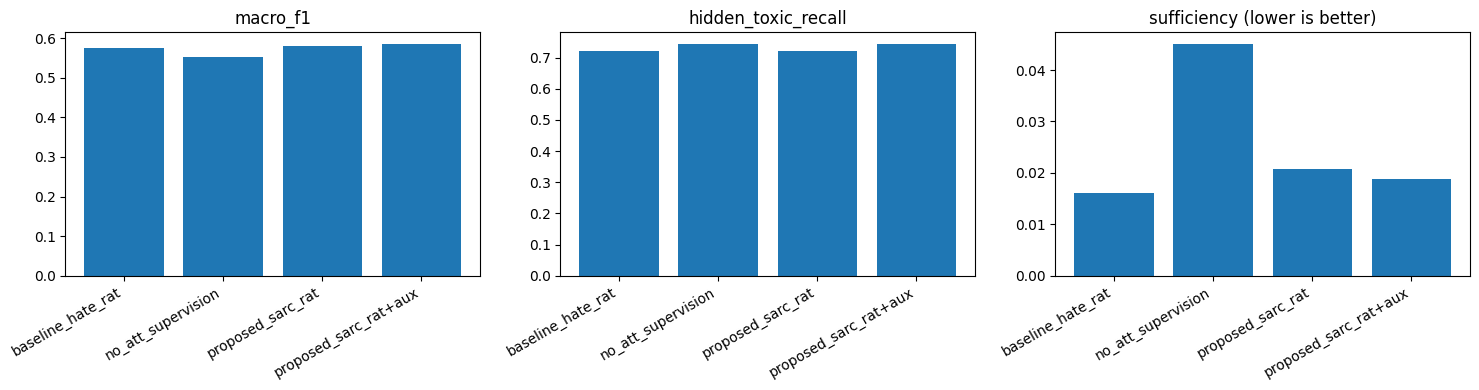

In [ ]:
metrics = ["acc", "macro_f1", "f1_offensive", "auroc", "hidden_toxic_recall", "token_f1", "auprc", "comprehensiveness", "sufficiency"]
print("Per-fold mean +- std (explainability metrics come from here)")
summary = res.groupby("mode")[[m for m in metrics if m in res.columns]].agg(["mean", "std"]).round(4)
display(summary); summary.to_csv("results_summary.csv")

# Pooled out-of-fold performance: every post is tested exactly once per mode/seed (less noisy than per-fold numbers)
pooled = []
for (mode, seed), g in pd.DataFrame(oof).groupby(["mode", "seed"]):
    y, pred, sarc = g.y.values, g.pred.values, g.sarc.values
    P_ = np.stack(g.probs.values); hs = hidden_hate_stats(y, pred, sarc)
    pooled.append(dict(mode=mode, seed=seed, n=len(g), acc=accuracy_score(y, pred), macro_f1=f1_score(y, pred, average="macro"),
                       auroc=roc_auc_score(y, P_, multi_class="ovr", average="macro"), **hs))
pooled = pd.DataFrame(pooled)
print("\nPooled out-of-fold performance (mean over seeds)")
display(pooled.groupby("mode").mean(numeric_only=True).round(4))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, mt in zip(ax, ["macro_f1", "hidden_toxic_recall", "sufficiency"]):
    g = res.groupby("mode")[mt]
    a.bar(range(len(g.mean())), g.mean().values, yerr=g.std().fillna(0).values)
    a.set_xticks(range(len(g.mean()))); a.set_xticklabels(g.mean().index, rotation=30, ha="right")
    a.set_title(mt + (" (lower is better)" if mt == "sufficiency" else ""))
plt.tight_layout(); plt.savefig("results.png", dpi=150); plt.show()

## 8. Further ideas

* Swap `CFG["backbone"]` for `GroNLP/hateBERT` or `cardiffnlp/twitter-roberta-base-hate` (often +1-3 F1 on toxic text).
* Sweep `lam` in {0.1, 1, 5} and `tau` in {0.1, 0.3, 1.0} on the validation folds.
* Add seeds (`CFG["seeds"] = [42, 43, 44]`) and average predicted probabilities across seeds as an ensemble.
* Oversample the 216 toxic+sarcastic posts, or increase `aux_w`, to give the sarcasm signal more weight.
* Add conversation context to each post (the paper's own stated limitation).